# Sparsh (I-JEPA, ViT-B) on one clip of the ICRA'18 Clothing dataset

Pipeline: **random clip → random $I_t$ and $I_{t-5}$ → Sparsh preprocessing → $x \in \mathbb{R}^{1\times 6\times H\times W}$ → HF backbone → patch tokens → visualizations** |

Kernel: the project `.venv` (Python 3.11 with torch 2.5.1, torchvision, opencv, einops, lightning).


## 0. Setup


In [1]:
import os, random, sys, warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

REPO = Path().resolve()
assert (REPO / "sparsh").is_dir(), "run this notebook from the repo root"
sys.path.insert(0, str(REPO / "sparsh"))
os.environ.setdefault("XFORMERS_DISABLED", "1")  # plain-PyTorch attention (same math)
warnings.filterwarnings("ignore", message=".*xFormers.*")

from tactile_ssl.data.digit.utils import (
    load_sample_from_buf,
    get_resize_transform,
)  # Sparsh's own preprocessing
from tactile_ssl.model.vision_transformer import vit_base  # Sparsh's own ViT

SEED = None  # set an int to reproduce a draw
REMOVE_BG = False  # Sparsh setting for GelSight'17; True = background subtraction (DIGIT / GelSight Mini style)
STRIDE = 5  # I_t and I_{t-5}
IMG_SIZE = (320, 240)  # (H, W) used by Sparsh for GelSight
PATCH = 16
DATA_DIR = REPO / "data" / "clothing"

seed = SEED if SEED is not None else random.SystemRandom().randrange(2**31)
rng = random.Random(seed)
print("seed:", seed)

/Users/baudoincoispeau/.pyenv/versions/3.11.4/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed: 256284371


## 1. Pick one clip at random


The clips were downloaded earlier into `data/clothing/<cloth>_<trial>/` (`GelSight_video.mp4` + `background.png`, from `Data_ICRA18.tar`). One of them is picked at random.


In [2]:
clips = sorted(p for p in DATA_DIR.iterdir() if (p / "GelSight_video.mp4").exists())
assert clips, f"no clips found in {DATA_DIR}"
clip_dir = rng.choice(clips)
cloth_idx, trial_idx = clip_dir.name.removeprefix("cloth").split("_trial")
print(f"{len(clips)} clip(s) available, selected: {clip_dir.relative_to(REPO)}")

2 clip(s) available, selected: data/clothing/cloth33_trial12


In [3]:
def read_video_rgb(path):
    cap = cv2.VideoCapture(str(path))
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )  # OpenCV decodes BGR; Sparsh works in RGB
    cap.release()
    return frames


frames = read_video_rgb(clip_dir / "GelSight_video.mp4")
bg = cv2.cvtColor(cv2.imread(str(clip_dir / "background.png")), cv2.COLOR_BGR2RGB)
print(
    f"{len(frames)} frames of {frames[0].shape} (H, W, C), uint8; background {bg.shape}"
)

89 frames of (480, 640, 3) (H, W, C), uint8; background (480, 640, 3)


## 2. Pick $I_t$ at random, then $I_{t-5}$


Frames 0–4 have no partner $I_{t-5}$, so $t$ is drawn uniformly from $\{5, \dots, N-1\}$.


t = 7, t-5 = 2  (N = 89)


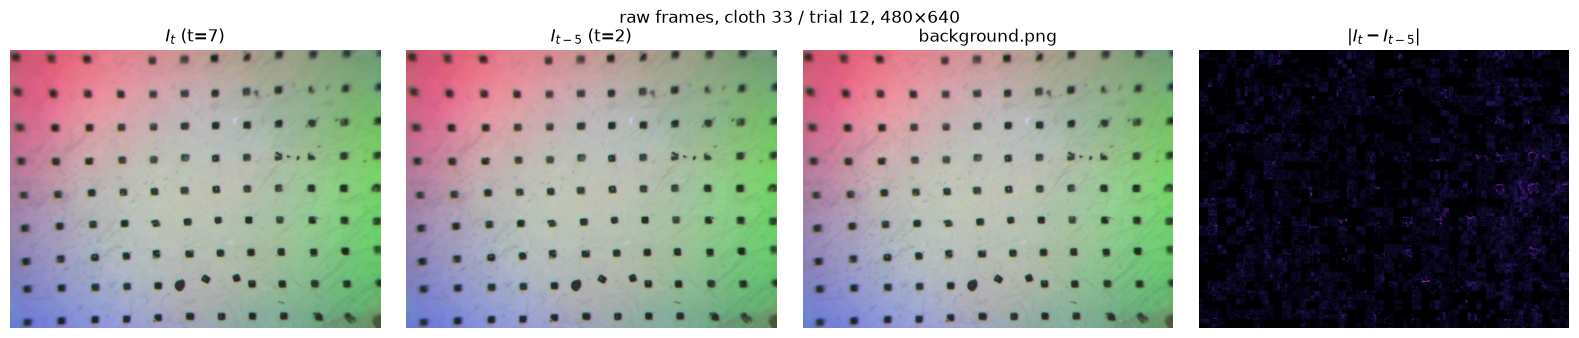

In [4]:
t = rng.randint(STRIDE, len(frames) - 1)
I_t, I_tm5 = frames[t], frames[t - STRIDE]
print(f"t = {t}, t-5 = {t - STRIDE}  (N = {len(frames)})")

fig, axs = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, img, title in zip(
    axs,
    [I_t, I_tm5, bg, np.abs(I_t.astype(int) - I_tm5.astype(int)).sum(-1)],
    [
        f"$I_t$ (t={t})",
        f"$I_{{t-5}}$ (t={t - STRIDE})",
        "background.png",
        r"$|I_t - I_{t-5}|$",
    ],
):
    ax.imshow(img, cmap="magma" if img.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f"raw frames, cloth {cloth_idx} / trial {trial_idx}, 480×640")
plt.tight_layout()
plt.show()

## 3. Sparsh preprocessing


This calls Sparsh's own functions, exactly as [`TextileDataset._get_tactile_images`](sparsh/tactile_ssl/data/vision_based_textile_probes.py) does:

1. `load_sample_from_buf(img, bg)`: optional background subtraction `(img − bg)/255 + 0.5`, then a 90° clockwise rotation from landscape to portrait (480×640 → 640×480), then the 4:3 crop, which does nothing here.
2. `get_resize_transform((320, 240))`: `Resize(320, 240)` followed by `ToTensor` → float in [0, 1], shape (3, 320, 240).


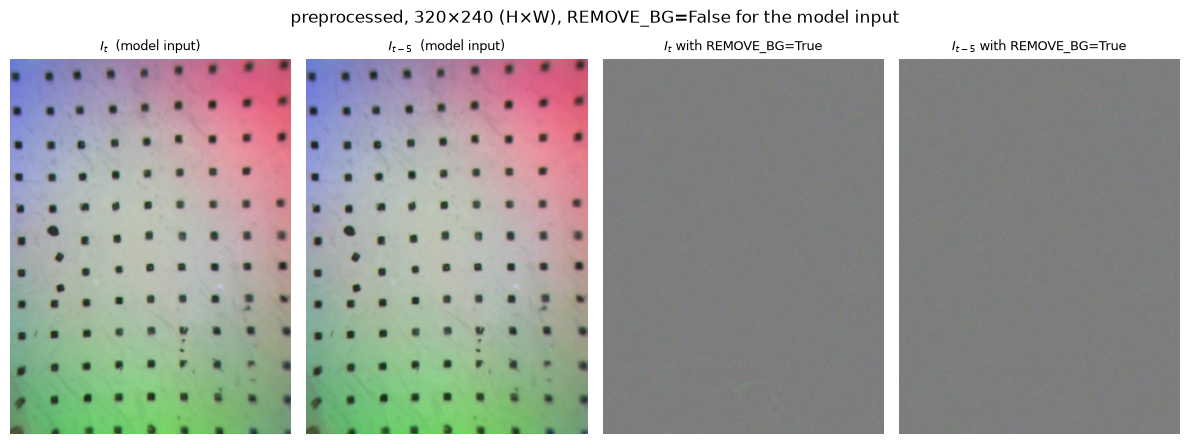

In [5]:
resize = get_resize_transform(IMG_SIZE)


def preprocess(img, remove_bg=REMOVE_BG):
    return resize(
        load_sample_from_buf(img, bg if remove_bg else None)
    )  # (3, 320, 240) in [0, 1]


x_t, x_tm5 = preprocess(I_t), preprocess(I_tm5)

show = lambda x: x.permute(1, 2, 0).numpy()
fig, axs = plt.subplots(1, 4, figsize=(12, 4.6))
panels = [
    (x_t, "$I_t$  (model input)"),
    (x_tm5, "$I_{t-5}$  (model input)"),
    (preprocess(I_t, remove_bg=not REMOVE_BG), f"$I_t$ with REMOVE_BG={not REMOVE_BG}"),
    (
        preprocess(I_tm5, remove_bg=not REMOVE_BG),
        f"$I_{{t-5}}$ with REMOVE_BG={not REMOVE_BG}",
    ),
]
for ax, (img, title) in zip(axs, panels):
    ax.imshow(show(img))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.suptitle(f"preprocessed, 320×240 (H×W), REMOVE_BG={REMOVE_BG} for the model input")
plt.tight_layout()
plt.show()

## 4. Build the input $x$ and check it


In [6]:
x = torch.cat([x_t, x_tm5], dim=0).unsqueeze(0)  # (1, 6, 320, 240)

assert x.shape == (1, 6, *IMG_SIZE), x.shape
assert x.dtype == torch.float32
assert 0.0 <= x.min() and x.max() <= 1.0, (
    "Sparsh feeds [0, 1] values, no mean/std normalization"
)
assert torch.equal(x[0, :3], x_t) and torch.equal(x[0, 3:], x_tm5), (
    "channels 0:3 = I_t, 3:6 = I_{t-5}"
)
assert IMG_SIZE[0] % PATCH == 0 and IMG_SIZE[1] % PATCH == 0
print(
    f"x {tuple(x.shape)} {x.dtype}, range [{x.min():.3f}, {x.max():.3f}], "
    f"mean |I_t - I_t-5| = {(x_t - x_tm5).abs().mean():.4f}"
)

x (1, 6, 320, 240) torch.float32, range [0.067, 0.937], mean |I_t - I_t-5| = 0.0025


## 5. Run the HF backbone


**Sparsh requires** an input of shape **(B, 6, 320, 240)**, float32 in [0, 1]: $I_t$ in channels 0:3 and $I_{t-5}$ in channels 3:6.
**Our input** `x` is **(1, 6, 320, 240)**, which matches.

Inside the backbone ([`facebook/sparsh-ijepa-base`](https://huggingface.co/facebook/sparsh-ijepa-base), ViT-Base):

1. **Patches** (`PatchEmbed`, a `Conv2d(6, 768, kernel_size=16, stride=16)`):
   - Patches are cut as usual. One channel, e.g. the red channel of $I_t$ ($R_t$, size 320×240), is split into a grid of $\frac{320}{16}\times\frac{240}{16} = 20 \times 15 = 300$ windows of 16×16.
   - The same grid is applied to all 6 channels: $R_t, G_t, B_t$ (frame $I_t$) and $R_{t-5}, G_{t-5}, B_{t-5}$ (frame $I_{t-5}$). Each grid position on the original frames therefore has **6 windows** of 16×16 = 6 × 256 = **1536 values**.
   - Keeping 6 × 300 separate tokens would be costly, so the 6 windows at the same position are **combined into one token**. They are flattened into a 1536-d vector and multiplied by a learned matrix $W$ (768 × 1536), plus a bias $b$ (768):
     $$z_{p,d} = \sum_{c=1}^{6}\ \sum_{i,j=1}^{16} W_{d,c,i,j}\; x_{c,i,j}^{(p)} + b_d, \qquad d = 1,\dots,768$$
     Each output feature $d$ is a **weighted sum over all 1536 values**: every pixel of every one of the 6 windows has its own weight, and there is a different set of weights for each of the 768 features. This is not one weight per window.
   - Result: **300 tokens of 768**, i.e. (B, 300, 768), not (B, 6, 300, 768). Colour and time ($I_t$ vs $I_{t-5}$) are fused in this very first layer ("early fusion"), as R, G, B already are in a standard RGB ViT. In the checkpoint, $W$ is stored as `patch_embed.proj.weight` with shape (768, 6, 16, 16).
2. **Positional embedding:** added by the backbone itself. It is a fixed sin/cos code, so there is nothing to do on your side.
3. **Register token:** one extra learnable token is appended to the 300 patch tokens. It carries no image content; it gives the transformer scratch space to store global information (Darcet et al., _Vision Transformers Need Registers_). It is dropped from the output.

**Output:** (1, 300, 768), one 768-d vector per patch.


In [7]:
ckpt_path = hf_hub_download("facebook/sparsh-ijepa-base", "ijepa_vitbase.safetensors")
state = load_file(ckpt_path)

encoder = vit_base(
    img_size=list(IMG_SIZE),
    in_chans=6,
    pos_embed_fn="sinusoidal",
    num_register_tokens=1,
)
assert torch.equal(
    encoder.pos_embed.frequency_bands, state["pos_embed.frequency_bands"]
)
encoder.load_state_dict(state, strict=True)
encoder.eval()
print(
    f"loaded {len(state)} tensors, strict=True; patch_embed {tuple(encoder.patch_embed.proj.weight.shape)}, "
    f"register tokens {encoder.num_register_tokens}"
)

with torch.no_grad():
    out = encoder.forward_features(x)
z = out["x_norm_patchtokens"]  # what encoder(x) returns
print("patch tokens   :", tuple(z.shape))
print("register token :", tuple(out["x_norm_regtokens"].shape))
assert z.shape == (1, (IMG_SIZE[0] // PATCH) * (IMG_SIZE[1] // PATCH), 768)

loaded 174 tensors, strict=True; patch_embed (768, 6, 16, 16), register tokens 1
patch tokens   : (1, 300, 768)
register token : (1, 1, 768)


## 6. Graph Laplacian of the patch grid


### 6.1 Patches on the 6 channels

The same 20 × 15 grid of 16×16 windows is laid on each of the 6 channels. Patch $p$ (node $p$ of the graph) is the stack of the 6 windows at the same position.

- Top row: the two frames $I_t$ and $I_{t-5}$.
- Middle row: the 3 channels of $I_t$.
- Bottom row: the 3 channels of $I_{t-5}$.

Each channel is shown in its own colour. The grid lines are white because red lines would disappear on the red channels.


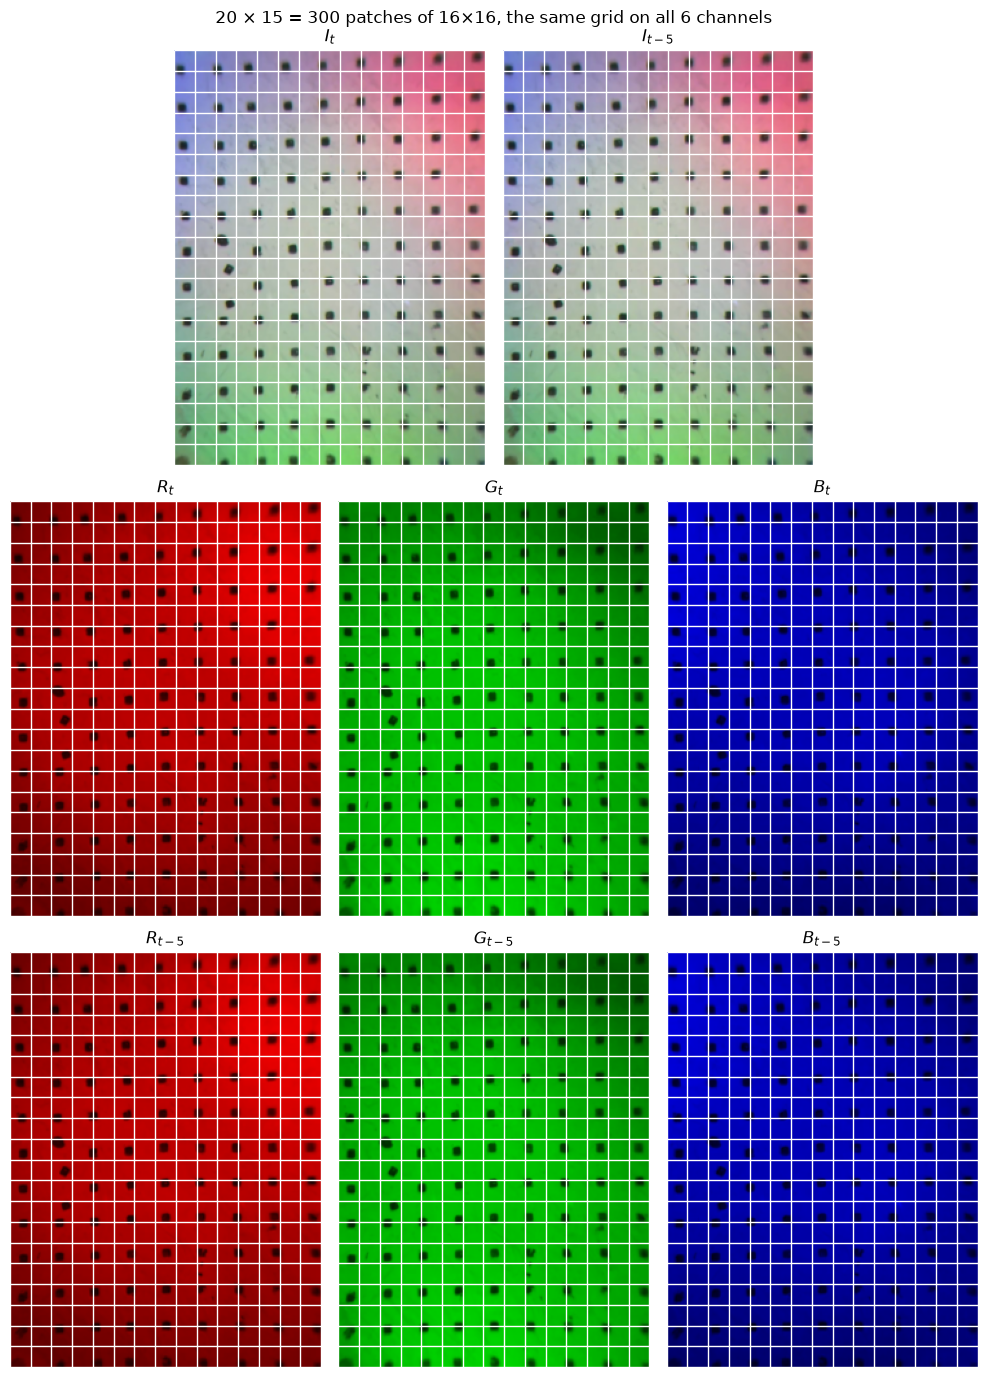

In [ ]:
GRID = (IMG_SIZE[0] // PATCH, IMG_SIZE[1] // PATCH)  # (20, 15)
channel_names = ["$R_t$", "$G_t$", "$B_t$", "$R_{t-5}$", "$G_{t-5}$", "$B_{t-5}$"]


def draw_patch_grid(ax):
    ax.hlines(
        np.arange(GRID[0] + 1) * PATCH - 0.5,
        -0.5,
        IMG_SIZE[1] - 0.5,
        colors="white",
        lw=1.0,
    )
    ax.vlines(
        np.arange(GRID[1] + 1) * PATCH - 0.5,
        -0.5,
        IMG_SIZE[0] - 0.5,
        colors="white",
        lw=1.0,
    )
    ax.axis("off")


fig = plt.figure(figsize=(10, 14))
gs = fig.add_gridspec(3, 6)
for k, (img, title) in enumerate(
    [(x_t, "$I_t$"), (x_tm5, "$I_{t-5}$")]
):  # row 1: the two frames, centred
    ax = fig.add_subplot(gs[0, 1 + 2 * k : 3 + 2 * k])
    ax.imshow(show(img))
    ax.set_title(title)
    draw_patch_grid(ax)
for c in range(6):  # row 2: channels of I_t, row 3: channels of I_{t-5}
    ax = fig.add_subplot(gs[1 + c // 3, 2 * (c % 3) : 2 * (c % 3) + 2])
    tinted = np.zeros((*IMG_SIZE, 3))
    tinted[..., c % 3] = x[0, c].numpy()  # channel c in its own colour: R, G or B
    ax.imshow(tinted)
    ax.set_title(channel_names[c])
    draw_patch_grid(ax)
plt.suptitle(
    f"{GRID[0]} × {GRID[1]} = {GRID[0] * GRID[1]} patches of 16×16, the same grid on all 6 channels"
)
plt.tight_layout()
plt.show()

### 6.2 Target graph

The target encoder sees all 300 patches, so its graph is the full grid: one node per patch, edges between patches sharing a side (4-neighbour). It is the same for every sample.


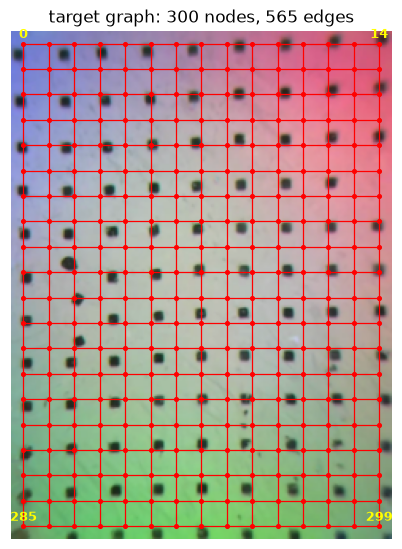

In [ ]:
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch, Rectangle

sys.path.insert(0, str(REPO))
from graph_laplacian.graph_laplacian import GridLaplacian

lap = GridLaplacian(GRID)  # strict 4-neighbour
N = lap.num_nodes
rows, cols = np.divmod(np.arange(N), GRID[1])  # node i = row * 15 + col
centers = np.stack(
    [(cols + 0.5) * PATCH - 0.5, (rows + 0.5) * PATCH - 0.5], axis=1
)  # (x, y) in pixels


def draw_graph(ax, nodes, color="red"):
    # nodes: indices in the 300-grid; edges: grid neighbours among these nodes
    idx = torch.as_tensor(nodes)
    i, j = (
        k.numpy()
        for k in torch.triu(lap.adjacency[idx][:, idx], diagonal=1).nonzero(
            as_tuple=True
        )
    )
    ax.add_collection(
        LineCollection(
            np.stack([centers[nodes[i]], centers[nodes[j]]], axis=1),
            colors=color,
            lw=0.9,
        )
    )
    ax.scatter(*centers[nodes].T, s=7, color=color, zorder=3)
    return len(i)


fig, ax = plt.subplots(figsize=(5, 6.6))
ax.imshow(show(x_t))
n_edges = draw_graph(ax, np.arange(N))
for node in [0, GRID[1] - 1, N - GRID[1], N - 1]:
    ax.annotate(
        str(node),
        centers[node],
        xytext=(0, 4),
        textcoords="offset points",
        color="yellow",
        fontsize=9,
        fontweight="bold",
        ha="center",
    )
ax.set_title(f"target graph: {N} nodes, {n_edges} edges")
ax.axis("off")
plt.show()

### 6.3 Context graph

Masks come from Sparsh's own [`IJEPAModule.sample_masks`](sparsh/tactile_ssl/algorithm/ijepa.py#L239). The pretraining settings are read from [config/model/ijepa_vit.yaml](sparsh/config/model/ijepa_vit.yaml) and [config/experiment/ijepa_vit.yaml](sparsh/config/experiment/ijepa_vit.yaml): 1 context block and 4 target blocks, with no overlap allowed. The context graph keeps only the K context patches and the edges between them.

Importing `tactile_ssl.algorithm` also loads `dinov2.py`, which imports xFormers unconditionally. xFormers needs CUDA and is not installed here, so an empty placeholder module is registered. The I-JEPA code never uses it.


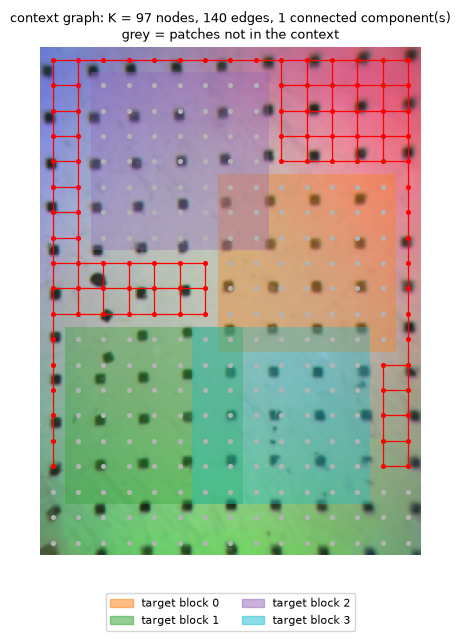

In [ ]:
import types

import torch.nn as nn
from omegaconf import OmegaConf

try:
    import xformers.ops  # noqa: F401
except (
    ImportError
):  # placeholder for dinov2.py's unconditional import; not used by I-JEPA
    sys.modules["xformers"] = types.ModuleType("xformers")
    sys.modules["xformers.ops"] = types.ModuleType("xformers.ops")
    sys.modules["xformers.ops"].fmha = None
from tactile_ssl.algorithm.ijepa import IJEPAModule

model_cfg = OmegaConf.load(REPO / "sparsh/config/model/ijepa_vit.yaml")
experiment_cfg = OmegaConf.load(REPO / "sparsh/config/experiment/ijepa_vit.yaml").model
ijepa = IJEPAModule(
    encoder=encoder,  # context encoder = HF weights
    predictor=nn.Identity(),  # not used here
    optim_cfg=None,
    lr_scheduler_cfg=None,
    wd_scheduler_cfg=None,
    encoder_mask_scale=tuple(model_cfg.encoder_mask_scale),
    predictor_mask_scale=tuple(model_cfg.predictor_mask_scale),
    aspect_ratio=tuple(model_cfg.aspect_ratio),
    min_keep_num_patches=model_cfg.min_keep_num_patches,
    allow_mask_overlap=experiment_cfg.allow_mask_overlap,
)
ijepa.generator.manual_seed(
    rng.randrange(2**31)
)  # training_step seeds it with the step counter
encoder_masks, predictor_masks = ijepa.sample_masks(x)  # 1 x (1, K), 4 x (1, N_tgt)
keep = encoder_masks[0]  # (1, K): indices of the context patches
K = keep.shape[1]
L_ctx = lap(keep_idx=keep)  # (1, K, K)
n_components = int((torch.linalg.eigvalsh(L_ctx[0]) < 1e-5).sum())

target_colors = ["tab:orange", "tab:green", "tab:purple", "tab:cyan"]
fig, ax = plt.subplots(figsize=(5, 6.6))
ax.imshow(show(x_t))
for mask, color in zip(predictor_masks, target_colors):
    for node in mask[0].numpy():
        ax.add_patch(
            Rectangle(
                (cols[node] * PATCH - 0.5, rows[node] * PATCH - 0.5),
                PATCH,
                PATCH,
                color=color,
                alpha=0.35,
                lw=0,
            )
        )
dropped = np.setdiff1d(np.arange(N), keep[0].numpy())
ax.scatter(*centers[dropped].T, s=7, color="0.7", zorder=3)
n_edges = draw_graph(ax, keep[0].numpy())
ax.legend(
    handles=[
        Patch(color=c, alpha=0.5, label=f"target block {k}")
        for k, c in enumerate(target_colors)
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    fontsize=8,
)
ax.set_title(
    f"context graph: K = {K} nodes, {n_edges} edges, {n_components} connected component(s)\n"
    "grey = patches not in the context",
    fontsize=9,
)
ax.axis("off")
plt.show()

### 6.4 Graph Laplacians and smoothing operator

- $L = D - A$ for both graphs: $L_{\text{tgt}}$ is (1, 300, 300) and $L_{\text{ctx}}$ is (1, K, K).
- Smoothing uses the heat kernel $S_\tau = e^{-\tau L}$. Each row of $S_\tau$ sums to 1, so $S_\tau X$ replaces every node by a weighted average of itself and its graph neighbourhood. Larger $\tau$ averages over a wider neighbourhood.
- $X_{\text{coarse}} = S_\tau X$ and $X_{\text{detail}} = X - X_{\text{coarse}}$.
- Right panels: one row of $S_\tau$, i.e. the averaging weights of one node. The row holds one value per node, and each node is a patch of the original grid. Instead of lining the values up, they are rearranged into the 20 × 15 patch grid, the patch-level picture of the frame. Square $j$ shows $S_{ij}$, the weight of patch $j$ in the coarse value of node $i$ (cyan box).
- The bottom row zooms into the middle of each Laplacian (green box, linked by green lines). Diagonal = degree of the node, −1 = the two nodes are neighbours.


L_tgt (1, 300, 300), L_ctx (1, 97, 97), S_tgt (1, 300, 300), S_ctx (1, 97, 97)


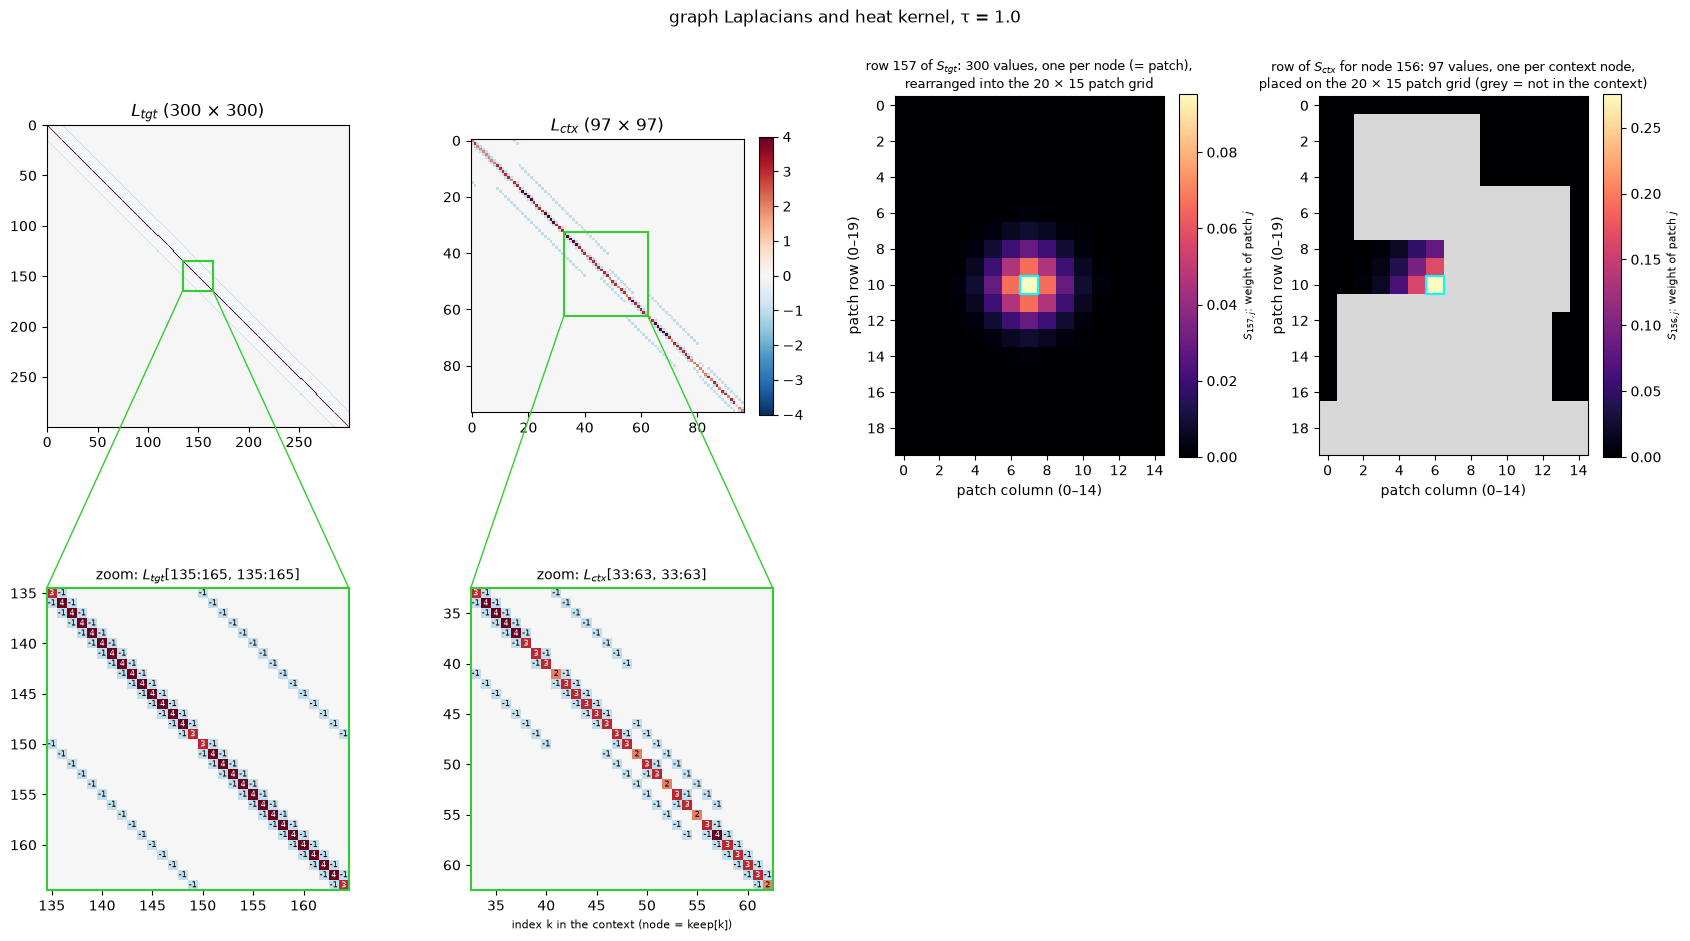

In [ ]:
TAU = 1.0  # smoothing scale

L_tgt = lap(batch_size=1)  # (1, 300, 300)
S_tgt = torch.linalg.matrix_exp(-TAU * L_tgt)  # (1, 300, 300)
S_ctx = torch.linalg.matrix_exp(-TAU * L_ctx)  # (1, K, K)
assert torch.allclose(S_tgt.sum(-1), torch.ones(1), atol=1e-5)
assert torch.allclose(S_ctx.sum(-1), torch.ones(1), atol=1e-5)
print(
    f"L_tgt {tuple(L_tgt.shape)}, L_ctx {tuple(L_ctx.shape)}, S_tgt {tuple(S_tgt.shape)}, S_ctx {tuple(S_ctx.shape)}"
)


def on_grid(values, nodes):
    # values at the given nodes -> (20, 15) map, NaN elsewhere
    img = np.full(N, np.nan)
    img[np.asarray(nodes)] = values
    return img.reshape(GRID)


centre = N // 2 + GRID[1] // 2
centre_ctx = int(
    np.argmin(np.linalg.norm(centers[keep[0].numpy()] - centers[centre], axis=1))
)
extent = (0, IMG_SIZE[1], IMG_SIZE[0], 0)

from matplotlib.patches import ConnectionPatch

fig = plt.figure(figsize=(17, 9.8))
gs = fig.add_gridspec(2, 4)
axs = [fig.add_subplot(gs[0, k]) for k in range(4)]
zoom_axs = [fig.add_subplot(gs[1, k]) for k in range(2)]
for ax, Lm, title in zip(
    axs[:2], [L_tgt[0], L_ctx[0]], ["$L_{tgt}$ (300 × 300)", f"$L_{{ctx}}$ ({K} × {K})"]
):
    im = ax.imshow(Lm.numpy(), cmap="RdBu_r", vmin=-4, vmax=4, interpolation="nearest")
    ax.set_title(title)
fig.colorbar(im, ax=axs[1], fraction=0.046)
node_ctx = int(keep[0, centre_ctx])
for ax, row, nodes, node, title in [
    (
        axs[2],
        S_tgt[0, centre],
        np.arange(N),
        centre,
        f"row {centre} of $S_{{tgt}}$: {N} values, one per node (= patch),\n"
        f"rearranged into the {GRID[0]} × {GRID[1]} patch grid",
    ),
    (
        axs[3],
        S_ctx[0, centre_ctx],
        keep[0].numpy(),
        node_ctx,
        f"row of $S_{{ctx}}$ for node {node_ctx}: {K} values, one per context node,\n"
        f"placed on the {GRID[0]} × {GRID[1]} patch grid (grey = not in the context)",
    ),
]:
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("0.85")  # light grey = not in the graph
    im = ax.imshow(on_grid(row.numpy(), nodes), interpolation="nearest", cmap=cmap)
    ax.add_patch(
        Rectangle(
            (node % GRID[1] - 0.5, node // GRID[1] - 0.5),
            1,
            1,
            fill=False,
            edgecolor="cyan",
            lw=1.5,
        )
    )
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(f"patch column (0–{GRID[1] - 1})")
    ax.set_ylabel(f"patch row (0–{GRID[0] - 1})")
    ax.set_xticks(range(0, GRID[1], 2))
    ax.set_yticks(range(0, GRID[0], 2))
    fig.colorbar(im, ax=ax, fraction=0.06).set_label(
        f"$S_{{{node}, j}}$: weight of patch $j$", fontsize=8
    )

ZOOM = 2 * GRID[1]  # 30 nodes = 2 grid rows
for ax, zax, Lm, name in zip(
    axs[:2], zoom_axs, [L_tgt[0], L_ctx[0]], ["L_{tgt}", "L_{ctx}"]
):
    size = min(ZOOM, Lm.shape[0])
    a = Lm.shape[0] // 2 - size // 2
    b = a + size
    block = Lm[a:b, a:b]
    ax.add_patch(
        Rectangle(
            (a - 0.5, a - 0.5), size, size, fill=False, edgecolor="limegreen", lw=1.5
        )
    )
    zax.imshow(
        block.numpy(),
        cmap="RdBu_r",
        vmin=-4,
        vmax=4,
        interpolation="nearest",
        extent=(a - 0.5, b - 0.5, b - 0.5, a - 0.5),
    )
    for i, j in block.nonzero().tolist():
        v = block[i, j].item()
        zax.text(
            a + j,
            a + i,
            f"{v:g}",
            ha="center",
            va="center",
            fontsize=6,
            color="white" if abs(v) >= 3 else "black",
        )
    zax.set_title(f"zoom: ${name}$[{a}:{b}, {a}:{b}]", fontsize=10)
    for spine in zax.spines.values():
        spine.set_edgecolor("limegreen")
        spine.set_linewidth(1.5)
    for corner_x, zoom_corner in [
        (a - 0.5, (0, 1)),
        (b - 0.5, (1, 1)),
    ]:  # box bottom corners -> zoom top corners
        fig.add_artist(
            ConnectionPatch(
                xyA=(corner_x, b - 0.5),
                coordsA=ax.transData,
                xyB=zoom_corner,
                coordsB=zax.transAxes,
                color="limegreen",
                lw=1,
            )
        )
zoom_axs[1].set_xlabel("index k in the context (node = keep[k])", fontsize=8)
plt.suptitle(f"graph Laplacians and heat kernel, τ = {TAU}")
plt.tight_layout()
plt.show()

### 6.5 Coarse and detail components

**Real frame (illustration only).** In our framework the decomposition is applied to the latent tokens only; the input frames are never modified. This figure only shows what the same smoothing does to raw pixels. Each patch $p$ carries its 6 × 16 × 16 pixel values, a 1536-d vector (exactly what `PatchEmbed` takes as input). So $X$ is (1, 300, 1536) for all patches, or (1, K, 1536) for the context patches only. Smoothing averages whole patches with the patches around them: pixel $(i, j)$ of a patch is mixed with pixel $(i, j)$ of the neighbouring patches. The figure shows the $I_t$ channels; light grey = patches not in the context.


real frame, all 300 patches: X (1, 300, 1536), ||detail|| / ||X|| = 0.138
real frame, context patches (K = 97): X (1, 97, 1536), ||detail|| / ||X|| = 0.134


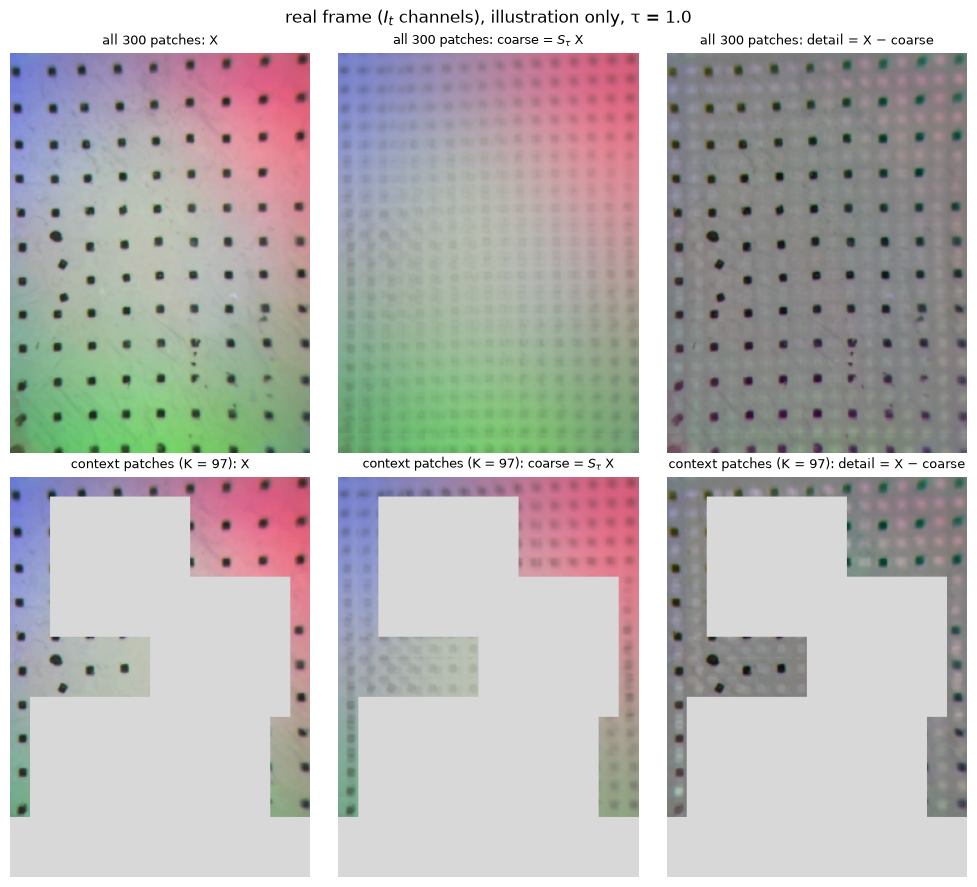

In [ ]:
from tactile_ssl.utils import patchify_image, patches_to_image


def split(S, X):
    coarse = S @ X
    detail = X - coarse
    assert torch.allclose(coarse + detail, X, atol=1e-6)
    return coarse, detail


def to_image(patches, nodes):
    # (1, K, 1536) patches at the given nodes -> (6, 320, 240), NaN where there is no patch
    full = torch.full((1, N, patches.shape[-1]), float("nan"))
    full[:, nodes] = patches
    return patches_to_image(full, PATCH, IMG_SIZE)[0]


def to_rgb(img, signed=False):
    # I_t channels of a (6, H, W) image as RGB; signed: 0.5 + v / (2 max|v|); NaN (no patch) -> light grey
    rgb = img[:3].permute(1, 2, 0).numpy()
    if signed:
        rgb = 0.5 + rgb / (2 * np.nanmax(np.abs(rgb)))
    return np.where(np.isnan(rgb), 0.85, np.clip(rgb, 0, 1))


P = patchify_image(x, PATCH)  # (1, 300, 1536)
P_ctx = P[:, keep[0]]  # (1, K, 1536)
branches = [
    ("all 300 patches", torch.arange(N), P, *split(S_tgt, P)),
    (f"context patches (K = {K})", keep[0], P_ctx, *split(S_ctx, P_ctx)),
]

fig, axs = plt.subplots(2, 3, figsize=(10, 9))
for row_axs, (name, nodes, X, coarse, detail) in zip(axs, branches):
    for ax, img, title, signed in zip(
        row_axs,
        [X, coarse, detail],
        ["X", "coarse = $S_τ$ X", "detail = X − coarse"],
        [False, False, True],
    ):
        ax.imshow(to_rgb(to_image(img, nodes), signed))
        ax.set_title(f"{name}: {title}", fontsize=9)
        ax.axis("off")
    print(
        f"real frame, {name}: X {tuple(X.shape)}, ||detail|| / ||X|| = {detail.norm() / X.norm():.3f}"
    )
plt.suptitle(f"real frame ($I_t$ channels), illustration only, τ = {TAU}")
plt.tight_layout()
plt.show()

**Embedded frame.**

- Target branch: the tokens $z$ (1, 300, 768) from step 5.
- Context branch: Sparsh's context encoder on the context patches only, `ijepa.context_encoder(x, encoder_masks)` as in [ijepa.py:314](sparsh/tactile_ssl/algorithm/ijepa.py#L314), giving (1, K, 768). The HF checkpoint only contains the target encoder, so the context encoder uses the same weights here.
- This is where the decomposition happens in our framework: on the tokens.
- Tokens are shown as RGB through the top-3 principal components of $z$. $X$ and coarse share one colour scale; detail gets its own symmetric scale, centred on grey.


embedded frame, target graph: X (1, 300, 768), ||detail|| / ||X|| = 0.626
embedded frame, context graph: X (1, 97, 768), ||detail|| / ||X|| = 0.617


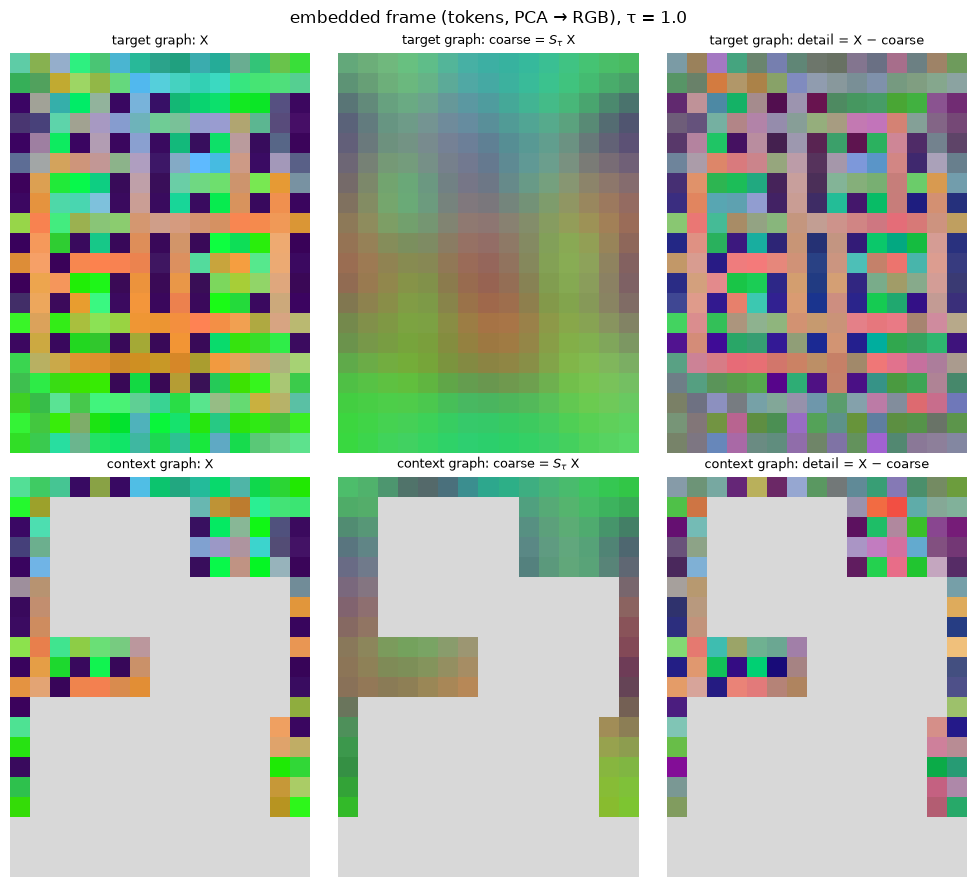

In [ ]:
with torch.no_grad():
    z_ctx = ijepa.context_encoder(x, encoder_masks)  # (1, K, 768), as in ijepa.py:314

torch.manual_seed(0)
z_mean = z[0].mean(0)
_, _, V = torch.pca_lowrank(z[0], q=3, center=True)
ref = (z[0] - z_mean) @ V
lo, hi = ref.min(0).values, ref.max(0).values


def pca_rgb(tokens, nodes, signed=False):
    # (1, K, 768) tokens -> (20, 15, 3) RGB through the top-3 PCs of z; nodes not given -> light grey
    if signed:  # detail: zero-mean differences, own symmetric scale
        proj = tokens[0] @ V
        proj = 0.5 + proj / (2 * proj.abs().max())
    else:  # X and coarse: same scale as z
        proj = ((tokens[0] - z_mean) @ V - lo) / (hi - lo)
    img = np.full((N, 3), 0.85)
    img[np.asarray(nodes)] = proj.clamp(0, 1).numpy()
    return img.reshape(*GRID, 3)


branches = [
    ("target graph", torch.arange(N), z, *split(S_tgt, z)),
    ("context graph", keep[0], z_ctx, *split(S_ctx, z_ctx)),
]

fig, axs = plt.subplots(2, 3, figsize=(10, 9))
for row_axs, (name, nodes, X, coarse, detail) in zip(axs, branches):
    for ax, tokens, title, signed in zip(
        row_axs,
        [X, coarse, detail],
        ["X", "coarse = $S_τ$ X", "detail = X − coarse"],
        [False, False, True],
    ):
        ax.imshow(
            pca_rgb(tokens, nodes, signed), extent=extent, interpolation="nearest"
        )
        ax.set_title(f"{name}: {title}", fontsize=9)
        ax.axis("off")
    print(
        f"embedded frame, {name}: X {tuple(X.shape)}, ||detail|| / ||X|| = {detail.norm() / X.norm():.3f}"
    )
plt.suptitle(f"embedded frame (tokens, PCA → RGB), τ = {TAU}")
plt.tight_layout()
plt.show()